# 3 · Preprocessing comparison

In [1]:
# setup
import csv, json
from pathlib import Path
import cv2, numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
X = ROOT / "experiments/preprocessing"
rgb = lambda f: cv2.cvtColor(f, cv2.COLOR_BGR2RGB)
is_ir = lambda f: cv2.cvtColor(f, cv2.COLOR_BGR2HSV)[..., 1].mean() < 8
# the preprocessing variants
_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
def clahe(f):
    lab = cv2.cvtColor(f, cv2.COLOR_BGR2LAB); lab[..., 0] = _clahe.apply(lab[..., 0]); return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)
_gamma = np.array([255 * (i / 255) ** 0.6 for i in range(256)], np.uint8)
VARIANTS = {"raw": lambda f: f, "clahe": clahe, "clahe_ir": lambda f: clahe(f) if is_ir(f) else f,
            "gamma_ir": lambda f: cv2.LUT(f, _gamma) if is_ir(f) else f}
DESC = {"raw": "no change", "clahe": "local contrast, all frames", "clahe_ir": "local contrast, night IR only", "gamma_ir": "brighten night IR only"}
# helpers to read the saved labels and images
def labels(variant, stem):
    p = next((X / f"labels_{variant}").glob(f"labels/*/{stem}.txt"))
    return [list(map(float, l.split())) for l in p.read_text().split("\n") if l.strip()]
def px(b, W, H): return [int((b[1]-b[3]/2)*W), int((b[2]-b[4]/2)*H), int((b[1]+b[3]/2)*W), int((b[2]+b[4]/2)*H)]
def image(stem): return cv2.imread(str(next((X / "labels_raw").glob(f"images/*/{stem}.jpg"))))

## Preprocessing examples

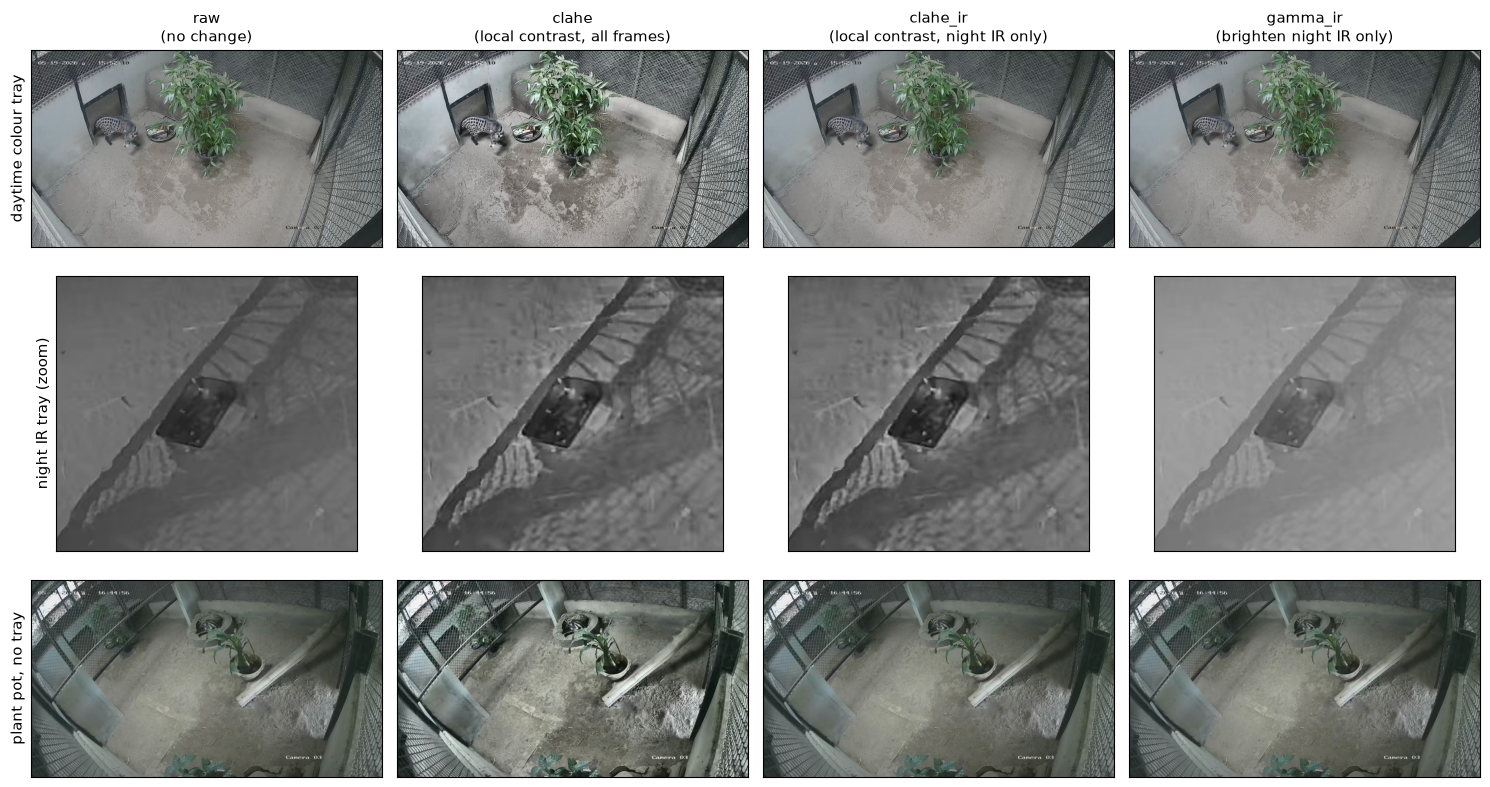

In [2]:
# a day tray, a night tray and the plant pot
picks = [("daytime colour tray", next((X / "labels_raw").glob("images/train/25690519193422801_*.jpg")).stem, None),
         ("night IR tray (zoom)", next((X / "labels_raw").glob("images/train/A03_*.jpg")).stem, "tray"),
         ("plant pot, no tray", next((X / "labels_raw").glob("images/train/neg_25690519194109670_*.jpg")).stem, None)]
fig, axs = plt.subplots(len(picks), 4, figsize=(15, 8.5))
for i, (title, stem, zoom) in enumerate(picks):
    f = image(stem); H, W = f.shape[:2]
    if zoom:
        T = px(next(b for b in labels("raw", stem) if b[0] == 1), W, H); p = 120
        f = f[max(0, T[1]-p):T[3]+p, max(0, T[0]-p):T[2]+p]
    for j, (k, fn) in enumerate(VARIANTS.items()):
        axs[i, j].imshow(rgb(fn(f))); axs[i, j].set_xticks([]); axs[i, j].set_yticks([])
        if i == 0: axs[i, j].set_title(f"{k}\n({DESC[k]})", fontsize=11)
        if j == 0: axs[i, j].set_ylabel(title, fontsize=11)
plt.tight_layout(); plt.show()

## SAM labelling

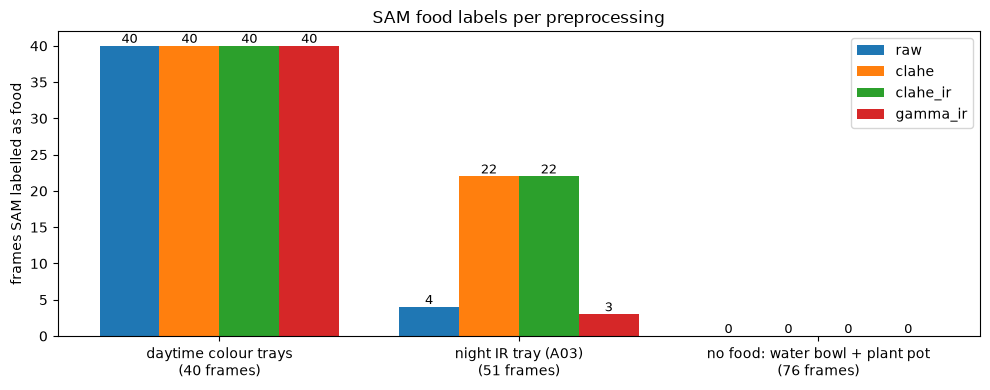

In [3]:
# which frames got a food label
def food_frames(v):
    out = {}
    for p in (X / f"labels_{v}").glob("labels/*/*.txt"):
        out[p.stem] = any(l.startswith("0 ") for l in p.read_text().split("\n"))
    return out
group = lambda k: "night IR tray (A03)" if k.startswith("A03") else ("no food: water bowl + plant pot" if k.startswith(("neg_", "A04")) else "daytime colour trays")
G = ["daytime colour trays", "night IR tray (A03)", "no food: water bowl + plant pot"]
ff = {v: food_frames(v) for v in VARIANTS}
# bar chart per frame group
fig, ax = plt.subplots(figsize=(10, 4)); w = 0.2
for j, v in enumerate(VARIANTS):
    vals = [sum(ff[v][k] for k in ff["raw"] if group(k) == g) for g in G]
    bars = ax.bar(np.arange(len(G)) + (j - 1.5) * w, vals, w, label=v)
    ax.bar_label(bars, fontsize=9)
tot = [sum(group(k) == g for k in ff["raw"]) for g in G]
ax.set_xticks(range(len(G)), [f"{g}\n({n} frames)" for g, n in zip(G, tot)]); ax.set_ylabel("frames SAM labelled as food")
ax.legend(); ax.set_title("SAM food labels per preprocessing"); plt.tight_layout(); plt.show()

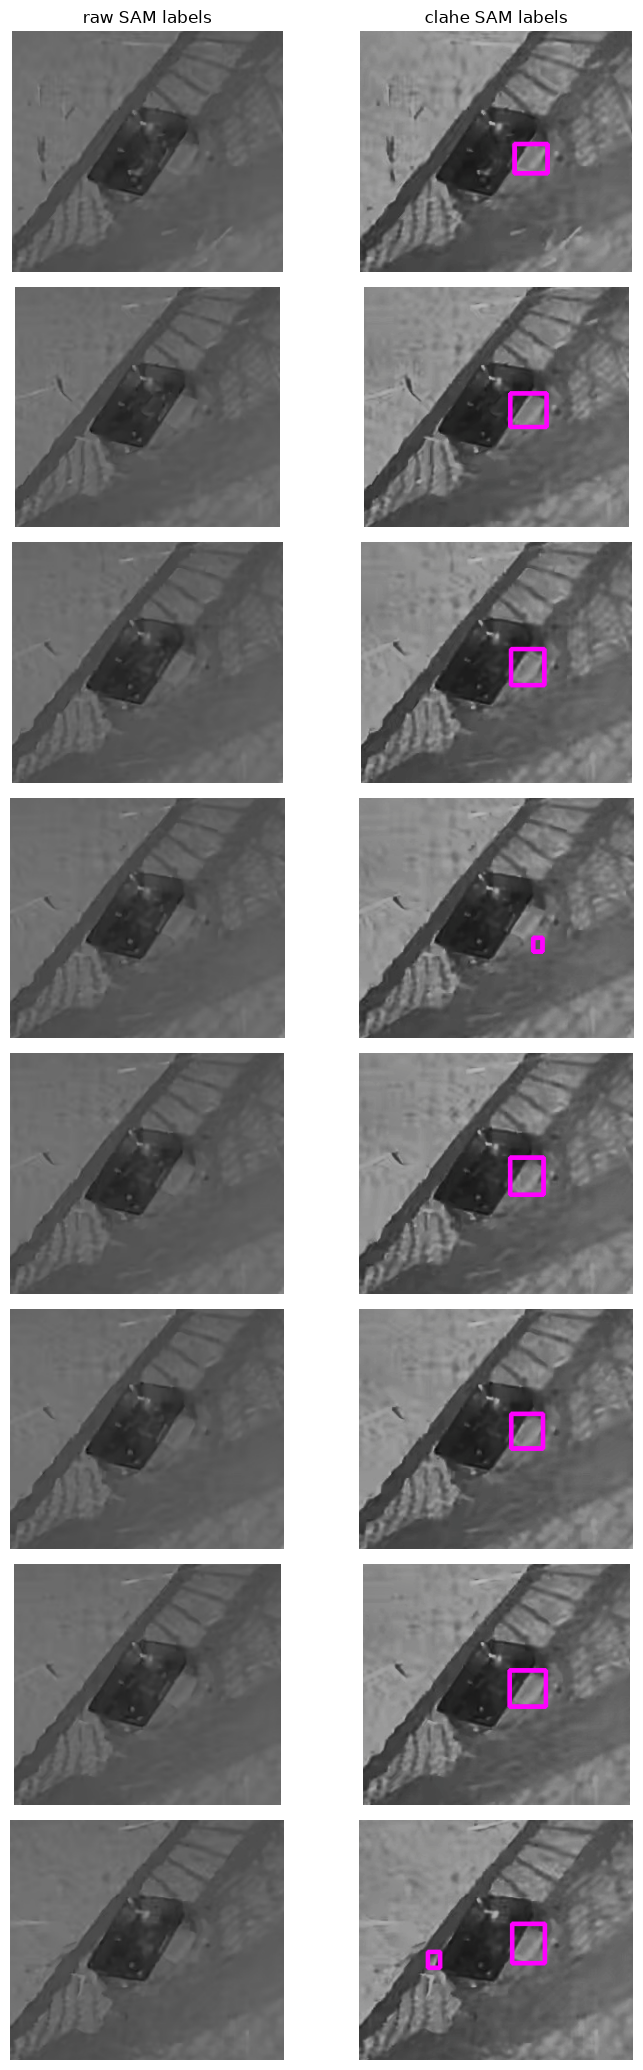

18 night frames differ (8 shown; all 18: /Users/win/dev/university/dip/project/experiments/preprocessing/ir_disagree.jpg)


In [4]:
# night frames where CLAHE and raw disagree, side by side
diff = sorted(k for k in ff["raw"] if group(k) == G[1] and ff["clahe"][k] != ff["raw"][k])
show = diff[:8]
fig, axs = plt.subplots(len(show), 2, figsize=(8, 2.6 * len(show)))
for i, stem in enumerate(show):
    f = image(stem); H, W = f.shape[:2]
    T = px(next(b for b in labels("raw", stem) if b[0] == 1), W, H); p = 70
    for j, v in enumerate(["raw", "clahe"]):
        g = VARIANTS[v](f).copy()
        for b in labels(v, stem):
            if b[0] == 0: x1, y1, x2, y2 = px(b, W, H); cv2.rectangle(g, (x1, y1), (x2, y2), (255, 0, 255), 3)
        axs[i, j].imshow(rgb(g[max(0, T[1]-p):T[3]+p, max(0, T[0]-p):T[2]+p])); axs[i, j].axis("off")
        if i == 0: axs[i, j].set_title(f"{v} SAM labels", fontsize=12)
plt.tight_layout(); plt.show()
print(f"{len(diff)} night frames differ ({len(show)} shown; all {len(diff)}: {X / 'ir_disagree.jpg'})")

## YOLO detection

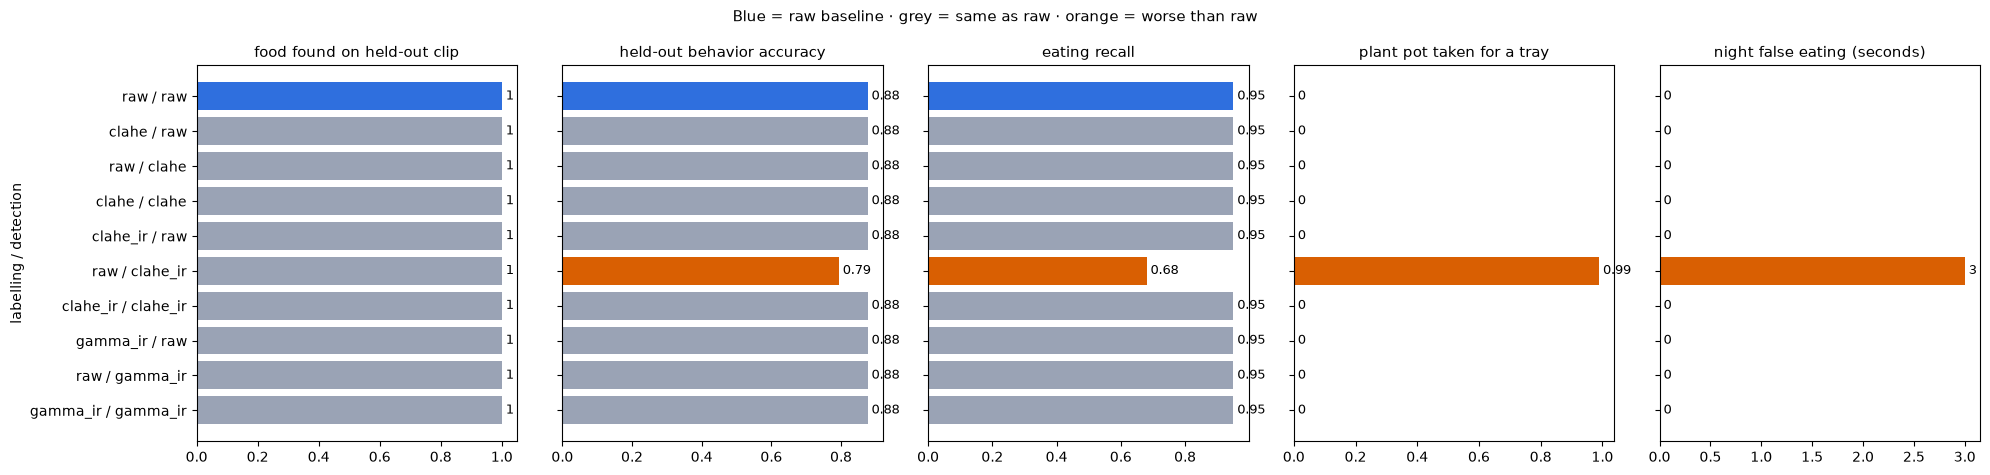

In [5]:
# results of the 10 models
res = list(csv.DictReader(open(X / "results.csv")))
for r in res:
    r["name"] = f"{r['labelling']} / {r['detection']}"
    a, n = map(int, r["behavior_match"].split("/")); r["behavior_acc"] = a / n
    r["epochs"] = sum(1 for _ in open(X / f"runs/{r['labelling']}__{r['detection']}/results.csv")) - 1
metrics = [("food_found", "food found on held-out clip", True), ("behavior_acc", "held-out behavior accuracy", True),
           ("eating_recall", "eating recall", True), ("pot_as_tray", "plant pot taken for a tray", False),
           ("night_false_eating", "night false eating (seconds)", False)]
# one bar chart per measure
fig, axs = plt.subplots(1, len(metrics), figsize=(20, 4.8), sharey=True)
y = np.arange(len(res))
for ax, (k, title, up) in zip(axs, metrics):
    vals = [float(r[k]) for r in res]
    colors = ["#2f6fde" if r["name"] == "raw / raw" else ("#d95f02" if (v < float(res[0][k]) if up else v > float(res[0][k])) else "#9aa3b5") for r, v in zip(res, vals)]
    ax.barh(y, vals, color=colors); ax.set_title(title, fontsize=11); ax.invert_yaxis()
    for yy, v in zip(y, vals): ax.text(v, yy, f" {v:.2f}".rstrip("0").rstrip(".") if v % 1 else f" {v:g}", va="center", fontsize=9)
axs[0].set_yticks(y, [f"{r['name']}" for r in res]); axs[0].set_ylabel("labelling / detection")
fig.suptitle("Blue = raw baseline · grey = same as raw · orange = worse than raw", fontsize=11); plt.tight_layout(); plt.show()

In [6]:
# the full table
cols = ["name", "food_found", "pot_as_tray", "behavior_match", "eating_precision", "eating_recall", "night_false_eating", "epochs"]
Markdown("| " + " | ".join(cols) + " |\n|" + "---|" * len(cols) + "\n" + "\n".join("| " + " | ".join(str(r[c]) for c in cols) + " |" for r in res))

| name | food_found | pot_as_tray | behavior_match | eating_precision | eating_recall | night_false_eating | epochs |
|---|---|---|---|---|---|---|---|
| raw / raw | 1.0 | 0.0 | 191/218 | 0.98 | 0.95 | 0 | 28 |
| clahe / raw | 1.0 | 0.0 | 191/218 | 0.98 | 0.95 | 0 | 17 |
| raw / clahe | 1.0 | 0.0 | 191/218 | 0.98 | 0.95 | 0 | 24 |
| clahe / clahe | 1.0 | 0.0 | 191/218 | 0.98 | 0.95 | 0 | 21 |
| clahe_ir / raw | 1.0 | 0.0 | 191/218 | 0.98 | 0.95 | 0 | 17 |
| raw / clahe_ir | 1.0 | 0.989 | 173/218 | 0.98 | 0.68 | 3 | 11 |
| clahe_ir / clahe_ir | 1.0 | 0.0 | 191/218 | 0.98 | 0.95 | 0 | 27 |
| gamma_ir / raw | 1.0 | 0.0 | 191/218 | 0.98 | 0.95 | 0 | 30 |
| raw / gamma_ir | 1.0 | 0.0 | 191/218 | 0.98 | 0.95 | 0 | 19 |
| gamma_ir / gamma_ir | 1.0 | 0.0 | 191/218 | 0.98 | 0.95 | 0 | 37 |